# 07b Classical residuals

A forecast can score well and still be built on a model whose assumptions do not hold. Here we look at what the
classical models leave behind. If the residuals still have a weekly pattern, the model missed something. If they
are far from normal, the textbook intervals and safety stock built on them will be off. We also list the fitted
parameters, so we can see what each model actually learned.

## Load

The orders chosen in 07a, and each series up to the warm-up origin, which is the data those orders were chosen on.

In [1]:
import os, sys, warnings
sys.path.append("../src")
os.environ["PYTHONPATH"] = os.path.abspath("../src")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ast import literal_eval
from joblib import Parallel, delayed
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox

from config import ROOT, INTERIM, TABLES, FIGS, ORIGINS, EVAL_ORIGINS, HORIZON, CATEGORIES, FIG_STYLE, NAMES
from metrics import mase_scale
import classical

plt.rcParams.update(FIG_STYLE)
written = []

sample = pd.read_csv(TABLES / "classical_sample_items.csv")
orders = pd.read_csv(TABLES / "classical_orders.csv")
for c in ["sarima_order", "sarima_sorder", "arima_order"]:
    orders[c] = orders[c].apply(literal_eval)
long_df = pd.concat([pd.read_csv(INTERIM / f"{c}_candidates.csv", parse_dates=["date"])
                     for c in ["foods", "hobbies", "household"]], ignore_index=True)
long_df["category"] = long_df["item_id"].str.split("_").str[0]
o0 = ORIGINS[0]
hist = {i: g.loc[g["date"] <= o0, "sales"].to_numpy(dtype=float) for i, g in long_df.groupby("item_id") if i in set(sample["item_id"])}
for cat in CATEGORIES:
    hist[cat] = long_df[(long_df["category"] == cat) & (long_df["date"] <= o0)].groupby("date")["sales"].sum().to_numpy(dtype=float)
hist["CA_TOTAL"] = long_df[long_df["date"] <= o0].groupby("date")["sales"].sum().to_numpy(dtype=float)
print(len(hist), "series")

154 series


## What each model assumes, and how we check it

| Model | What it assumes | How we check |
|---|---|---|
| Holt-Winters additive | a level, a trend and a weekly pattern of fixed size explain the series; the rest is noise with no pattern | Ljung-Box on the residuals at lags 7 and 14, and their ACF |
| ARIMA | after d differences the series is stationary; the residuals are white noise; the fitted model is stationary and invertible | d from KPSS (05); Ljung-Box; AR and MA roots outside the unit circle |
| SARIMA | as ARIMA, with the weekly pattern carried by seasonal terms | as ARIMA, seasonal roots included |
| all of them, for intervals | residuals are roughly normal with a constant spread | Jarque-Bera |

We drop the first 28 residuals of each fit, because state-space models start with large residuals while they settle.

In [2]:
LAGS = [7, 14]

def tests(resid):
    """Ljung-Box (lags 7 and 14) and Jarque-Bera on one residual series."""
    r = np.asarray(resid, dtype=float)[28:]
    r = r[np.isfinite(r)]
    lb = acorr_ljungbox(r, lags=LAGS, return_df=True)["lb_pvalue"].to_numpy()
    jb = stats.jarque_bera(r).pvalue
    return {"lb_p7": lb[0], "lb_p14": lb[1], "jb_p": jb, "lb_pass": bool((lb > 0.05).all()), "jb_pass": bool(jb > 0.05)}

def diagnose(name, y_all, row):
    y = classical.last_days(y_all)
    out, params = [], []
    fits = {"sarima": lambda: classical.fit_sarima(y, row["sarima_order"], row["sarima_sorder"])[0],
            "arima": lambda: classical.fit_sarima(y, row["arima_order"])[0],
            "hw_add": lambda: classical.fit_hw(y)}
    for model, fit in fits.items():
        try:
            res = fit()
        except Exception:
            out.append({"series": name, "model": model, "fit_failed": True})
            continue
        d = {"series": name, "model": model, "fit_failed": False, **tests(res.resid)}
        if model in ("sarima", "arima"):
            ar, ma = np.abs(getattr(res, "arroots", [])), np.abs(getattr(res, "maroots", []))
            d["stationary_invertible"] = bool((len(ar) == 0 or ar.min() > 1) and (len(ma) == 0 or ma.min() > 1))
            p = dict(zip(res.param_names, res.params))
        else:
            p = {k: res.params.get(k) for k in ["smoothing_level", "smoothing_trend", "smoothing_seasonal", "damping_trend"]}
        out.append(d)
        params.append({"series": name, "model": model, **{k: float(v) for k, v in p.items() if v is not None}})
    return out, params

o = orders.set_index("series")
res = Parallel(n_jobs=8)(delayed(diagnose)(name, y, o.loc[name]) for name, y in hist.items())
diag = pd.DataFrame([r for rows, _ in res for r in rows])
params = pd.DataFrame([p for _, ps in res for p in ps])
for c in ["lb_pass", "jb_pass", "stationary_invertible"]:     # yes/no with blanks (Holt-Winters has no roots)
    diag[c] = diag[c].astype(float)
diag["level"] = np.where(diag["series"].isin(CATEGORIES + ["CA_TOTAL"]), "aggregate", "item")
params["level"] = np.where(params["series"].isin(CATEGORIES + ["CA_TOTAL"]), "aggregate", "item")
diag.to_csv(TABLES / "diagnostics_items.csv", index=False)
params.to_csv(TABLES / "parameters_items.csv", index=False)
written += [TABLES / "diagnostics_items.csv", TABLES / "parameters_items.csv"]
print(len(diag), "model fits checked")

462 model fits checked


## How many pass

In [3]:
summ = diag.groupby(["level", "model"]).agg(n=("series", "size"), fit_failed=("fit_failed", "mean"),
                                            ljung_box_pass=("lb_pass", "mean"), normality_pass=("jb_pass", "mean"),
                                            roots_ok=("stationary_invertible", "mean")).reset_index()
summ.to_csv(TABLES / "diagnostics_summary.csv", index=False)
written.append(TABLES / "diagnostics_summary.csv")
summ.round(3)

,level,model,n,fit_failed,ljung_box_pass,normality_pass,roots_ok
0,aggregate,arima,4,0.0,0.000,0.000,1.00
1,aggregate,hw_add,4,0.0,0.250,0.000,NaN
2,aggregate,sarima,4,0.0,0.000,0.000,0.75
3,item,arima,150,0.0,0.287,0.000,1.00
4,item,hw_add,150,0.0,0.473,0.007,NaN
5,item,sarima,150,0.0,0.820,0.007,1.00


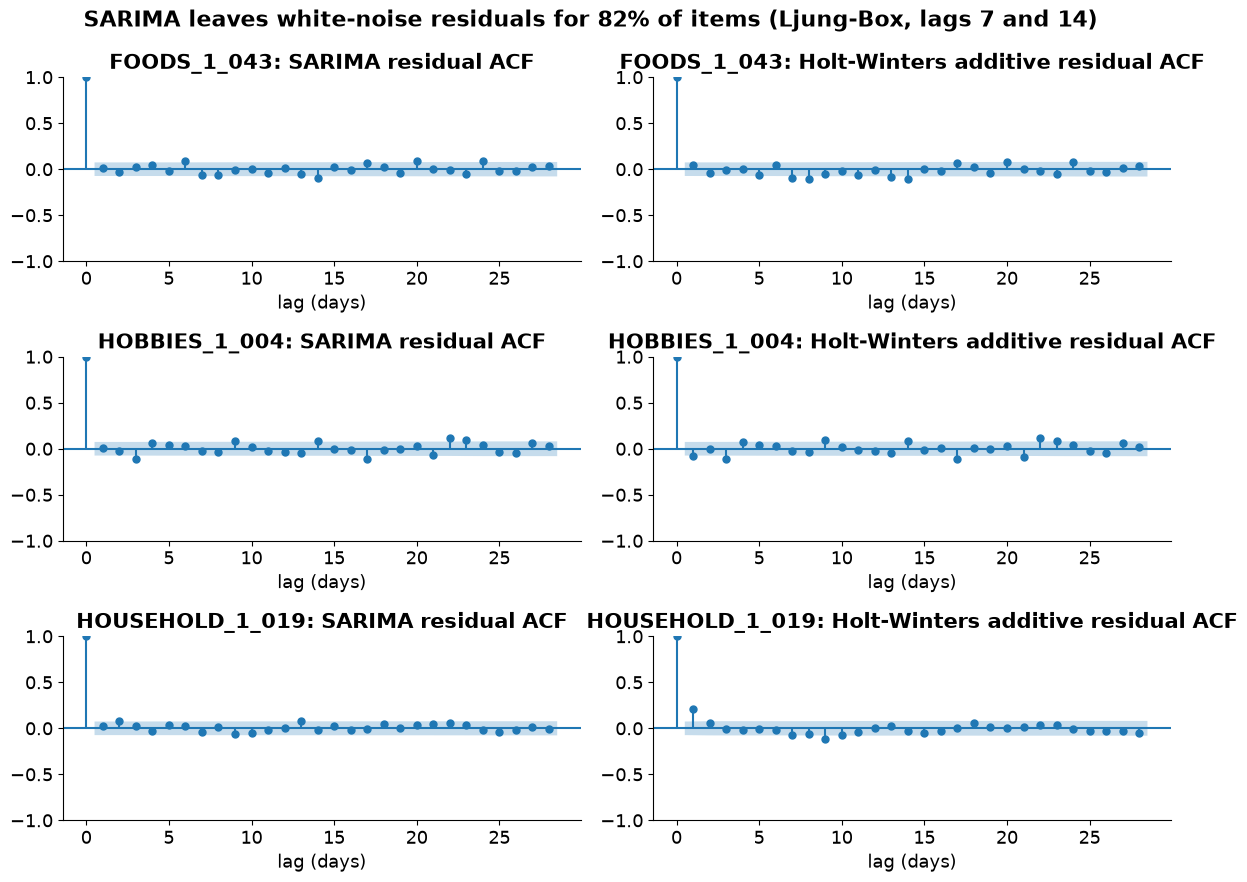

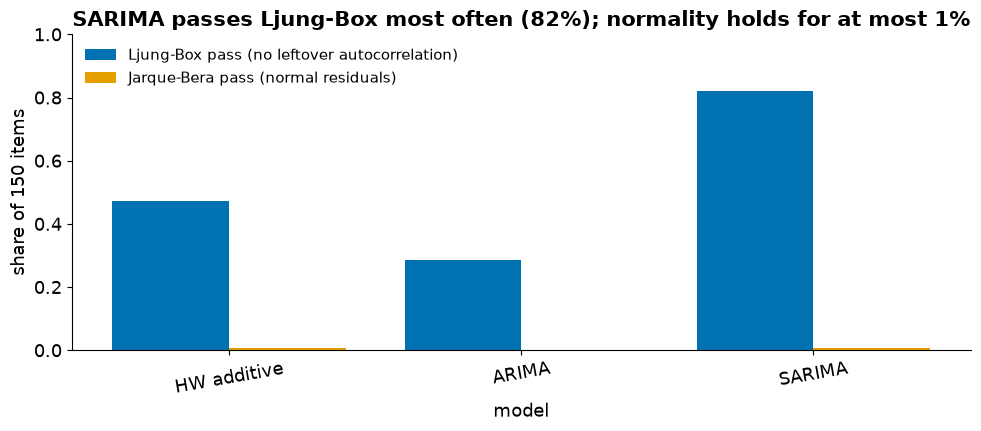

In [4]:
ex = sample.groupby("category")["item_id"].first().tolist()
fig, axes = plt.subplots(len(ex), 2, figsize=(12, 3 * len(ex)))
for row, item in zip(axes, ex):
    y = classical.last_days(hist[item])
    r = o.loc[item]
    for ax, (model, res) in zip(row, [("sarima", classical.fit_sarima(y, r["sarima_order"], r["sarima_sorder"])[0]),
                                      ("hw_add", classical.fit_hw(y))]):
        plot_acf(np.asarray(res.resid)[28:], lags=28, ax=ax, title=f"{item}: {NAMES[model]} residual ACF")
        ax.set_xlabel("lag (days)")
share = summ[(summ["level"] == "item") & (summ["model"] == "sarima")]["ljung_box_pass"].iloc[0]
fig.suptitle(f"SARIMA leaves white-noise residuals for {share:.0%} of items (Ljung-Box, lags 7 and 14)", fontsize=16, fontweight="bold")
fig.tight_layout()
fig.savefig(FIGS / "residual_acf.png")
written.append(FIGS / "residual_acf.png")
plt.show()

s = summ[summ["level"] == "item"].set_index("model").loc[["hw_add", "arima", "sarima"]]
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(s))
ax.bar(x - 0.2, s["ljung_box_pass"], 0.4, color="#0072B2", label="Ljung-Box pass (no leftover autocorrelation)")
ax.bar(x + 0.2, s["normality_pass"], 0.4, color="#E69F00", label="Jarque-Bera pass (normal residuals)")
ax.set_xticks(x, [NAMES[m].replace("Holt-Winters ", "HW ") for m in s.index], rotation=10)
ax.set_ylim(0, 1)
ax.set_xlabel("model")
ax.set_ylabel("share of 150 items")
best = s["ljung_box_pass"].idxmax()
ax.set_title(f"{NAMES[best]} passes Ljung-Box most often ({s.loc[best, 'ljung_box_pass']:.0%}); "
             f"normality holds for at most {s['normality_pass'].max():.0%}")
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
fig.savefig(FIGS / "residual_checks_pass.png")
written.append(FIGS / "residual_checks_pass.png")
plt.show()

## What the models learned

In [5]:
items_orders = orders[orders["level"] == "item"]
print("most common SARIMA orders (products):")
print(items_orders.apply(lambda r: f"{r['sarima_order']}{r['sarima_sorder'][:3]}", axis=1).value_counts().head(8).to_string())
print("\nmost common ARIMA orders (products):")
print(items_orders["arima_order"].astype(str).value_counts().head(5).to_string())
print(f"\nd: {items_orders['d'].value_counts().sort_index().to_dict()}   D: {items_orders['D'].value_counts().sort_index().to_dict()}")

keep = ["smoothing_level", "smoothing_trend", "smoothing_seasonal", "damping_trend", "intercept",
        "ar.L1", "ar.L2", "ma.L1", "ma.L2", "ar.S.L7", "ma.S.L7", "sigma2"]
p_items = params[params["level"] == "item"]
ps = p_items.groupby("model")[[k for k in keep if k in params]].median().T
ps.to_csv(TABLES / "parameters_summary.csv")
written.append(TABLES / "parameters_summary.csv")
print("\nmedian fitted parameters over the 150 products (blank = not part of that model):")
print(ps.round(3).to_string())
print("\ntotals:")
print(orders[orders["level"] == "aggregate"][["series", "d", "D", "sarima_order", "sarima_sorder", "arima_order"]].to_string(index=False))

most common SARIMA orders (products):
(1, 1, 2)(1, 0, 1)    32
(0, 1, 1)(1, 0, 1)    22
(1, 1, 1)(1, 0, 1)    17
(2, 1, 1)(1, 0, 1)    16
(0, 1, 2)(1, 0, 1)     8
(2, 1, 2)(1, 0, 1)     8
(0, 0, 0)(1, 0, 1)     6
(2, 0, 2)(1, 0, 1)     4

most common ARIMA orders (products):
arima_order
(1, 1, 1)    29
(2, 1, 2)    26
(2, 1, 1)    24
(0, 1, 2)    16
(0, 1, 1)    14

d: {0: 29, 1: 121}   D: {0: 150}

median fitted parameters over the 150 products (blank = not part of that model):
model                arima  hw_add  sarima
smoothing_level        NaN   0.072     NaN
smoothing_trend        NaN   0.000     NaN
smoothing_seasonal     NaN   0.000     NaN
damping_trend          NaN     NaN     NaN
intercept            4.200     NaN   0.119
ar.L1                0.311     NaN   0.229
ar.L2               -0.096     NaN   0.053
ma.L1               -0.949     NaN  -0.965
ma.L2                0.262     NaN   0.392
ar.S.L7                NaN     NaN   0.996
ma.S.L7                NaN     NaN  -0.968


## SARIMA on the totals: the model or the numbers?

In 07a some SARIMA fits on the totals went wrong without an error: forecasts of zero, or of hundreds of thousands a
day. The totals run to thousands of units, and the optimiser can struggle with numbers that size. So we refit the
same orders on the totals divided by 1,000 and multiply the forecast back. This is only a check: the 07a numbers
stay as they are.

In [6]:
rows = []
for cat in CATEGORIES + ["CA_TOTAL"]:
    s = long_df if cat == "CA_TOTAL" else long_df[long_df["category"] == cat]
    s = s.groupby("date")["sales"].sum()
    r = o.loc[cat]
    for origin in EVAL_ORIGINS:
        y = classical.last_days(s[s.index <= origin].to_numpy(dtype=float))
        act = s.reindex(pd.date_range(origin + pd.Timedelta(days=1), periods=HORIZON)).to_numpy()
        sc = mase_scale(s[s.index <= origin].to_numpy(dtype=float))
        for unit, k in [("units", 1.0), ("thousands", 1000.0)]:
            fc, ok, fb = classical.sarima_forecast(y / k, r["sarima_order"], r["sarima_sorder"], HORIZON)
            rows.append({"series": cat, "origin": origin, "scale": unit, "converged": ok, "fallback": fb,
                         "mase": np.mean(np.abs(act - fc * k)) / sc})
rescale = pd.DataFrame(rows)
rescale.to_csv(TABLES / "sarima_totals_rescaled.csv", index=False)
written.append(TABLES / "sarima_totals_rescaled.csv")
rescale.groupby(["series", "scale"]).agg(mean_mase=("mase", "mean"), converged=("converged", "mean"),
                                         fallbacks=("fallback", "sum")).round(3)

mean_mase  converged  fallbacks
series    scale                                     
CA_TOTAL  thousands      0.864      0.167          0
          units          0.870      0.333          1
FOODS     thousands      0.834      0.167          0
          units          1.976      0.000          0
HOBBIES   thousands      0.699      0.500          0
          units          0.674      0.333          0
HOUSEHOLD thousands      0.928      0.000          0
          units          4.710      0.500          1

In [7]:
assert set(diag["model"]) == {"sarima", "arima", "hw_add"}
assert diag.groupby("model")["series"].nunique().eq(len(hist)).all()
print("fits that failed:", int(diag["fit_failed"].sum()), "of", len(diag))

fits that failed: 0 of 462


## What we found

SARIMA leaves the cleanest residuals: 82% of products pass Ljung-Box at lags 7 and 14, so for most of them there is
no autocorrelation left over. Holt-Winters passes for 47% and ARIMA for only 29%. ARIMA has no weekly terms at
all, so a weekly echo is left in its residuals, and the ACF plots show exactly that.

Normal residuals almost never happen: Jarque-Bera passes for at most 0.7% of products. Daily sales are counts with
a long right tail, so this is no surprise. It does not hurt the point forecasts, but it means intervals and safety
stock that assume normal errors will be wrong, which is why 11a builds intervals from the errors themselves.

Every product-level ARIMA and SARIMA is stationary and invertible. The typical SARIMA uses one difference, no
seasonal difference, and a weekly AR term close to 1 (median 0.996) with a weekly MA term close to -1. That pair
behaves almost like a seasonal difference, so SARIMA ended up doing what `nsdiffs` did not ask for. Holt-Winters
chose small smoothing (about 0.07-0.10 for the level) and kept the weekly pattern fixed.

The totals were a numbers problem, not a model problem: in thousands of units the FOODS total gives a MASE of
0.834 instead of 1.976. We also found that these fits on the raw totals give different answers inside a joblib
worker (07a) and in the main process (here): HOUSEHOLD comes out at 1.145 there and 4.710 here. Each notebook
repeats exactly when rerun, so this is sensitivity to the numerical setup, not randomness. Fitting at product
level, or rescaling, avoids it.

## What comes next

`08a_break_detection` looks for the moments when a product's level shifts, which is what the conflicting stationarity tests in 05 hinted at.

In [8]:
# files this notebook wrote
for p in written:
    print(p.relative_to(ROOT), f"{p.stat().st_size / 1e3:,.0f} KB")

outputs\tables\diagnostics_items.csv 48 KB
outputs\tables\parameters_items.csv 50 KB
outputs\tables\diagnostics_summary.csv 0 KB
outputs\figures\residual_acf.png 154 KB
outputs\figures\residual_checks_pass.png 56 KB
outputs\tables\parameters_summary.csv 0 KB
outputs\tables\sarima_totals_rescaled.csv 3 KB
